# PS 26132 — Price Forecasting with District & Grade Adjustments

This notebook has 4 parts:
1. **Aggregate** raw data into a dense state-level series + district/grade offset tables
2. **Train** the XGBoost forecasting model on the state-level series
3. **Local price predictor** — combine model prediction + district offset + grade offset
4. **Sale-window recommendation** — turn the local prediction into sell-now/wait advice

Run cells top to bottom. Part 1 only needs to be rerun when you refetch raw data.

## Part 1: Aggregate data (with outlier filtering)

Produces three outputs from the raw CSV:
- `aggregated_prices.csv` — dense Commodity+State+Date series (for training)
- `district_offsets.csv` — how much each district's price historically differs from its state average
- `grade_offsets.csv` — how much each grade's price historically differs from its state average

**Why offsets instead of training District/Grade directly into the model:** splitting the time series by District or Grade makes each series too sparse, which breaks lag features. So the core model trains on the dense State-level series, and District/Grade are applied as a separate multiplicative adjustment at prediction time.

**Outlier filtering (important):** real mandi data has data-entry errors — occasional prices that are 100x-1000x too high/low (typos, decimal mistakes, unit mismatches). Even ONE such row distorts the daily average, and then corrupts every lag/rolling feature that touches it for the next 30 days. Since different crops have very different normal price ranges, we can't use one fixed threshold — instead we compute a per-commodity "normal range" using the IQR (interquartile range) method, in a first pass over the data, then filter in the second pass.

In [1]:
import pandas as pd
import numpy as np

# ============ CONFIG ============
INPUT_CSV = "mandi_prices_5years.csv"
CHUNK_SIZE = 100_000

STATE_SERIES_CSV = "aggregated_prices.csv"
DISTRICT_OFFSETS_CSV = "district_offsets.csv"
GRADE_OFFSETS_CSV = "grade_offsets.csv"

TARGET_CROPS = ["Onion", "Tomato", "Potato", "Wheat", "Rice"]

MIN_DAYS_FOR_OFFSET = 30

# IQR multiplier for outlier bounds. Standard convention uses 1.5x for "mild"
# outliers, but mandi prices genuinely have wide legitimate swings (seasonal
# spikes are real, not errors) — 3x is more conservative and only catches
# the truly absurd values (typos, extra zeros), not real price spikes.
IQR_MULTIPLIER = 3.0
# =================================


In [2]:
def compute_price_bounds():
    """
    Pass 1: scan just Commodity + Modal_Price (cheap — 2 columns only) to
    compute a safe [lower, upper] price range per commodity, using IQR.
    """
    print("Pass 1: scanning for per-commodity price bounds (outlier detection)...")
    samples = {crop: [] for crop in TARGET_CROPS}

    for chunk in pd.read_csv(
        INPUT_CSV, chunksize=CHUNK_SIZE, usecols=["Commodity", "Modal_Price"], low_memory=False
    ):
        chunk["Commodity"] = chunk["Commodity"].astype(str).str.strip()
        chunk = chunk[chunk["Commodity"].isin(TARGET_CROPS)]
        chunk["Modal_Price"] = pd.to_numeric(chunk["Modal_Price"], errors="coerce")
        chunk = chunk.dropna(subset=["Modal_Price"])
        chunk = chunk[chunk["Modal_Price"] > 0]

        for crop, group in chunk.groupby("Commodity"):
            samples[crop].append(group["Modal_Price"])

    bounds = {}
    for crop, parts in samples.items():
        if not parts:
            continue
        all_prices = pd.concat(parts, ignore_index=True)
        q1, q3 = all_prices.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower = max(0, q1 - IQR_MULTIPLIER * iqr)
        upper = q3 + IQR_MULTIPLIER * iqr
        bounds[crop] = (lower, upper)
        n_outliers = ((all_prices < lower) | (all_prices > upper)).sum()
        print(f"  {crop}: normal range [{lower:.0f}, {upper:.0f}]  "
              f"(Q1={q1:.0f}, Q3={q3:.0f})  -> {n_outliers:,} outlier rows will be dropped")

    return bounds


price_bounds = compute_price_bounds()
price_bounds


Pass 1: scanning for per-commodity price bounds (outlier detection)...
  Onion: normal range [0, 9500]  (Q1=1500, Q3=3500)  -> 420 outlier rows will be dropped
  Tomato: normal range [0, 8500]  (Q1=1500, Q3=3250)  -> 616 outlier rows will be dropped
  Potato: normal range [0, 8200]  (Q1=1000, Q3=2800)  -> 353 outlier rows will be dropped
  Wheat: normal range [1796, 3248]  (Q1=2419, Q3=2626)  -> 9,416 outlier rows will be dropped
  Rice: normal range [600, 6550]  (Q1=3150, Q3=4000)  -> 1,855 outlier rows will be dropped


{'Onion': (0, 9500.0),
 'Tomato': (0, 8500.0),
 'Potato': (0, 8200.0),
 'Wheat': (1796.0599999999995, 3248.4550000000004),
 'Rice': (600.0, 6550.0)}

In [3]:
def clean_chunk(chunk, price_bounds):
    """Filter to target crops, clean prices/dates, strip whitespace, drop outliers."""
    chunk = chunk[chunk["Commodity"].isin(TARGET_CROPS)].copy()
    if len(chunk) == 0:
        return chunk

    for col in ["State", "District", "Market", "Commodity", "Grade", "Variety"]:
        if col in chunk.columns:
            chunk[col] = chunk[col].astype(str).str.strip()

    # Fix known duplicate spellings for the same real state — otherwise the
    # same state gets silently split into two different "states" in training,
    # producing wildly different (and wrong) predictions depending on which
    # spelling is queried.
    STATE_NAME_FIXES = {
        "Keralam": "Kerala",
        "Uttrakhand": "Uttarakhand",
    }
    chunk["State"] = chunk["State"].replace(STATE_NAME_FIXES)

    chunk["Modal_Price"] = pd.to_numeric(chunk["Modal_Price"], errors="coerce")
    chunk = chunk.dropna(subset=["Modal_Price"])
    chunk = chunk[chunk["Modal_Price"] > 0]

    chunk["Arrival_Date"] = pd.to_datetime(
        chunk["Arrival_Date"], format="%d/%m/%Y", errors="coerce"
    )
    chunk = chunk.dropna(subset=["Arrival_Date"])

    # ---- Outlier filtering using the per-commodity bounds from Pass 1 ----
    lower_map = chunk["Commodity"].map(lambda c: price_bounds.get(c, (0, np.inf))[0])
    upper_map = chunk["Commodity"].map(lambda c: price_bounds.get(c, (0, np.inf))[1])
    chunk = chunk[(chunk["Modal_Price"] >= lower_map) & (chunk["Modal_Price"] <= upper_map)]

    return chunk


def merge_duplicate_dates(df, group_cols):
    return (
        df.groupby(group_cols)["Modal_Price"]
        .mean()
        .reset_index()
        .sort_values(group_cols)
    )


In [4]:
print(f"Pass 2: reading {INPUT_CSV} in chunks of {CHUNK_SIZE:,} rows and aggregating...")

state_parts, district_parts, grade_parts = [], [], []
total_seen, total_kept = 0, 0

for i, chunk in enumerate(pd.read_csv(INPUT_CSV, chunksize=CHUNK_SIZE, low_memory=False), start=1):
    total_seen += len(chunk)
    chunk = clean_chunk(chunk, price_bounds)
    total_kept += len(chunk)

    if len(chunk) == 0:
        continue

    state_parts.append(
        chunk.groupby(["Commodity", "State", "Arrival_Date"])["Modal_Price"].mean().reset_index()
    )
    district_parts.append(
        chunk.groupby(["Commodity", "State", "District", "Arrival_Date"])["Modal_Price"].mean().reset_index()
    )
    grade_parts.append(
        chunk.groupby(["Commodity", "State", "Grade", "Arrival_Date"])["Modal_Price"].mean().reset_index()
    )

    print(f"  chunk {i}: seen {total_seen:,} rows so far, kept {total_kept:,} "
          f"(after target-crop filter + outlier removal)")

print(f"\nTotal: seen {total_seen:,}, kept {total_kept:,}")


Pass 2: reading mandi_prices_5years.csv in chunks of 100,000 rows and aggregating...
  chunk 1: seen 100,000 rows so far, kept 15,832 (after target-crop filter + outlier removal)
  chunk 2: seen 200,000 rows so far, kept 31,794 (after target-crop filter + outlier removal)
  chunk 3: seen 300,000 rows so far, kept 47,270 (after target-crop filter + outlier removal)
  chunk 4: seen 400,000 rows so far, kept 62,978 (after target-crop filter + outlier removal)
  chunk 5: seen 500,000 rows so far, kept 78,846 (after target-crop filter + outlier removal)
  chunk 6: seen 600,000 rows so far, kept 94,701 (after target-crop filter + outlier removal)
  chunk 7: seen 700,000 rows so far, kept 110,299 (after target-crop filter + outlier removal)
  chunk 8: seen 800,000 rows so far, kept 126,499 (after target-crop filter + outlier removal)
  chunk 9: seen 900,000 rows so far, kept 142,635 (after target-crop filter + outlier removal)
  chunk 10: seen 1,000,000 rows so far, kept 158,133 (after target

In [5]:
print("Combining chunks and resolving cross-chunk duplicates...")
state_day = merge_duplicate_dates(
    pd.concat(state_parts, ignore_index=True), ["Commodity", "State", "Arrival_Date"]
)
district_day = merge_duplicate_dates(
    pd.concat(district_parts, ignore_index=True), ["Commodity", "State", "District", "Arrival_Date"]
)
grade_day = merge_duplicate_dates(
    pd.concat(grade_parts, ignore_index=True), ["Commodity", "State", "Grade", "Arrival_Date"]
)

state_day.to_csv(STATE_SERIES_CSV, index=False)
print(f"Saved state-level series: {len(state_day):,} rows -> {STATE_SERIES_CSV}")
state_day.head()


Combining chunks and resolving cross-chunk duplicates...
Saved state-level series: 67,221 rows -> aggregated_prices.csv


,Commodity,State,Arrival_Date,Modal_Price
0,Onion,Andaman and Nicobar,2026-08-24,4500.0
1,Onion,Andhra Pradesh,2024-08-07,4800.0
2,Onion,Andhra Pradesh,2024-08-08,4800.0
3,Onion,Andhra Pradesh,2024-08-09,3770.0
4,Onion,Andhra Pradesh,2024-08-10,4800.0


In [6]:
# ---- District offsets ----
merged = district_day.merge(
    state_day, on=["Commodity", "State", "Arrival_Date"], suffixes=("_district", "_state")
)
merged["ratio"] = merged["Modal_Price_district"] / merged["Modal_Price_state"]

district_offsets = (
    merged.groupby(["Commodity", "State", "District"])["ratio"]
    .agg(offset_ratio="mean", num_days="count")
    .reset_index()
)
before = len(district_offsets)
district_offsets = district_offsets[district_offsets["num_days"] >= MIN_DAYS_FOR_OFFSET]
print(f"District offsets: kept {len(district_offsets)}/{before} "
      f"(dropped ones with fewer than {MIN_DAYS_FOR_OFFSET} matching days)")
district_offsets.to_csv(DISTRICT_OFFSETS_CSV, index=False)
district_offsets.head()


District offsets: kept 1743/1972 (dropped ones with fewer than 30 matching days)


,Commodity,State,District,offset_ratio,num_days
1,Onion,Andhra Pradesh,Kurnool,0.999077,433
2,Onion,Andhra Pradesh,YSR Kadapa,1.011737,31
3,Onion,Assam,Barpeta,0.949894,49
5,Onion,Assam,Dhemaji,1.160229,73
6,Onion,Assam,Dhubri,0.814613,80


In [7]:
# ---- Grade offsets (same logic) ----
merged_g = grade_day.merge(
    state_day, on=["Commodity", "State", "Arrival_Date"], suffixes=("_grade", "_state")
)
merged_g["ratio"] = merged_g["Modal_Price_grade"] / merged_g["Modal_Price_state"]

grade_offsets = (
    merged_g.groupby(["Commodity", "State", "Grade"])["ratio"]
    .agg(offset_ratio="mean", num_days="count")
    .reset_index()
)
before = len(grade_offsets)
grade_offsets = grade_offsets[grade_offsets["num_days"] >= MIN_DAYS_FOR_OFFSET]
print(f"Grade offsets: kept {len(grade_offsets)}/{before} "
      f"(dropped ones with fewer than {MIN_DAYS_FOR_OFFSET} matching days)")
grade_offsets.to_csv(GRADE_OFFSETS_CSV, index=False)
grade_offsets.head()


Grade offsets: kept 452/667 (dropped ones with fewer than 30 matching days)


,Commodity,State,Grade,offset_ratio,num_days
1,Onion,Andhra Pradesh,FAQ,0.985163,364
2,Onion,Andhra Pradesh,Local,1.002337,62
3,Onion,Andhra Pradesh,Non-FAQ,1.108226,48
4,Onion,Assam,FAQ,0.994329,253
6,Onion,Assam,Local,1.152326,73


## Part 2: Train the forecasting model

Trains on the dense state-level series. Uses a **time-based split** (never random, for time series). Prints feature importances afterward so you can see which features are actually contributing.

In [8]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import joblib

# ============ CONFIG ============
MODEL_OUT = "price_model.pkl"
FORECAST_DAYS_AHEAD = 7
TEST_MONTHS = 2
MIN_HISTORY_DAYS = 60  # skip crop/state series with too little history to be useful
# =================================

raw = pd.read_csv(STATE_SERIES_CSV, parse_dates=["Arrival_Date"])
raw.head()


,Commodity,State,Arrival_Date,Modal_Price
0,Onion,Andaman and Nicobar,2026-08-24,4500.0
1,Onion,Andhra Pradesh,2024-08-07,4800.0
2,Onion,Andhra Pradesh,2024-08-08,4800.0
3,Onion,Andhra Pradesh,2024-08-09,3770.0
4,Onion,Andhra Pradesh,2024-08-10,4800.0


In [9]:
def build_features(df):
    """Add lag, rolling-average, and seasonality features to one crop+state series."""
    df = df.sort_values("Arrival_Date").reset_index(drop=True)

    for lag in [1, 7, 14, 30]:
        df[f"lag_{lag}"] = df["Modal_Price"].shift(lag)

    df["roll_avg_7"] = df["Modal_Price"].shift(1).rolling(7).mean()
    df["roll_avg_30"] = df["Modal_Price"].shift(1).rolling(30).mean()

    df["day_of_week"] = df["Arrival_Date"].dt.dayofweek
    df["month"] = df["Arrival_Date"].dt.month

    df["target"] = df["Modal_Price"].shift(-FORECAST_DAYS_AHEAD)

    return df


print("Building features per crop/state group...")
feature_frames = []
skipped = 0
for (commodity, state), group in raw.groupby(["Commodity", "State"]):
    if len(group) < MIN_HISTORY_DAYS:
        skipped += 1
        continue
    feature_frames.append(build_features(group))

if skipped:
    print(f"  (skipped {skipped} crop/state group(s) with fewer than {MIN_HISTORY_DAYS} days of history)")

data = pd.concat(feature_frames, ignore_index=True)
data = data.dropna()
data.head()


Building features per crop/state group...
  (skipped 10 crop/state group(s) with fewer than 60 days of history)


,Commodity,State,Arrival_Date,Modal_Price,lag_1,lag_7,lag_14,lag_30,roll_avg_7,roll_avg_30,day_of_week,month,target
30,Onion,Andhra Pradesh,2024-09-25,4800.0,4800.0,4800.0,4800.0,4800.0,4800.0,4748.350000,2,9,4800.0
31,Onion,Andhra Pradesh,2024-09-26,4800.0,4800.0,4800.0,4800.0,4800.0,4800.0,4748.350000,3,9,4800.0
32,Onion,Andhra Pradesh,2024-09-27,4800.0,4800.0,4800.0,4800.0,3770.0,4800.0,4748.350000,4,9,4800.0
33,Onion,Andhra Pradesh,2024-09-28,4800.0,4800.0,4800.0,4800.0,4800.0,4800.0,4782.683333,5,9,4800.0
34,Onion,Andhra Pradesh,2024-09-29,4800.0,4800.0,4800.0,4800.0,4800.0,4800.0,4782.683333,6,9,4800.0


In [10]:
feature_cols = [
    "current_price", "lag_1", "lag_7", "lag_14", "lag_30",
    "roll_avg_7", "roll_avg_30", "day_of_week", "month",
]

# "current_price" is today's actual known price (the row's own Modal_Price) —
# safe to use since we're predicting FORECAST_DAYS_AHEAD days into the FUTURE,
# not today. No leakage. Often the single strongest predictor.
data["current_price"] = data["Modal_Price"]

data = pd.get_dummies(data, columns=["Commodity", "State"], prefix=["crop", "state"])
dummy_cols = [c for c in data.columns if c.startswith("crop_") or c.startswith("state_")]
feature_cols += dummy_cols

cutoff_date = data["Arrival_Date"].max() - pd.DateOffset(months=TEST_MONTHS)
train = data[data["Arrival_Date"] <= cutoff_date]
test = data[data["Arrival_Date"] > cutoff_date]

print(f"Train rows: {len(train):,}  |  Test rows: {len(test):,}")
print(f"Train period: up to {cutoff_date.date()}  |  Test period: after {cutoff_date.date()}")

X_train, y_train = train[feature_cols], train["target"]
X_test, y_test = test[feature_cols], test["target"]


Train rows: 57,460  |  Test rows: 5,670
Train period: up to 2026-06-21  |  Test period: after 2026-06-21


In [11]:
baseline_pred = test["lag_1"]
baseline_mae = mean_absolute_error(y_test, baseline_pred)
print(f"Baseline (naive 'tomorrow = today') MAE: {baseline_mae:.2f}")


Baseline (naive 'tomorrow = today') MAE: 228.36


In [12]:
from sklearn.metrics import r2_score
print("Training XGBoost model...")
model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
model.fit(X_train, y_train)

preds = model.predict(X_test)
mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)
print(f"XGBoost MAE:  {mae:.2f}  ({'BETTER' if mae < baseline_mae else 'WORSE'} than baseline)")
print(f"XGBoost RMSE: {rmse:.2f}")
print(f"XGBoost R2_Score : {r2}")
if mae >= baseline_mae:
    print("\n!! WARNING: model is not beating the naive baseline. "
          "This usually means not enough training data yet, or features "
          "need tuning. Don't ship this as-is — investigate before demo.")

joblib.dump({"model": model, "feature_cols": feature_cols}, MODEL_OUT)
print(f"\nModel saved to {MODEL_OUT}")


Training XGBoost model...
XGBoost MAE:  211.93  (BETTER than baseline)
XGBoost RMSE: 359.60
XGBoost R2_Score : 0.8998793645258427

Model saved to price_model.pkl


In [13]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("Feature importance (higher = more the model relies on it):")
print(importances.to_string())

near_zero = importances[importances < 0.01]
if len(near_zero) > 0:
    print(f"\nNote: {len(near_zero)} feature(s) contributing almost nothing (<1%): {list(near_zero.index)}")


Feature importance (higher = more the model relies on it):
current_price              0.463446
lag_1                      0.258886
lag_7                      0.056760
roll_avg_7                 0.017504
crop_Rice                  0.011279
state_Nagaland             0.010888
crop_Tomato                0.009666
state_Chandigarh           0.008922
state_Andhra Pradesh       0.008599
crop_Wheat                 0.008274
month                      0.007660
state_Uttarakhand          0.006944
state_West Bengal          0.006663
state_Tamil Nadu           0.006487
roll_avg_30                0.006464
state_Tripura              0.006227
state_Karnataka            0.006077
crop_Onion                 0.006064
state_Meghalaya            0.005980
state_NCT of Delhi         0.005846
state_Manipur              0.005825
crop_Potato                0.005719
state_Kerala               0.005515
state_Gujarat              0.005270
state_Telangana            0.004964
lag_14                     0.004845
lag_3

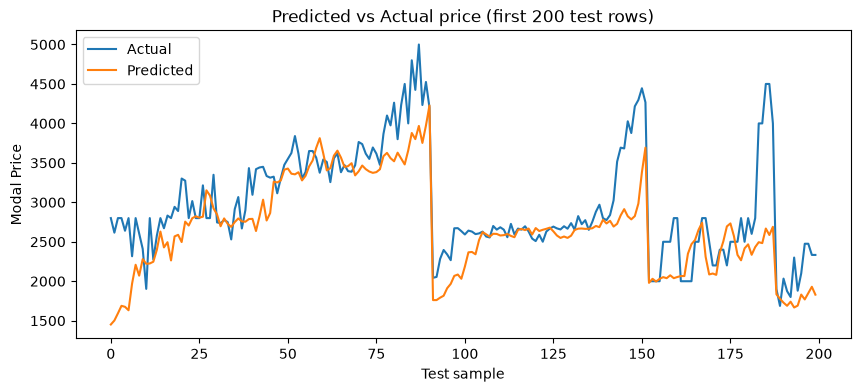

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:200], label="Actual")
plt.plot(preds[:200], label="Predicted")
plt.legend()
plt.title("Predicted vs Actual price (first 200 test rows)")
plt.xlabel("Test sample")
plt.ylabel("Modal Price")
plt.show()


## Part 2b: Hyperparameter tuning + model comparison

Two things here:
1. **Proper hyperparameter search** using `RandomizedSearchCV` with `TimeSeriesSplit` — NOT regular `KFold`/random CV, because random CV would let the model "peek" at future rows while validating on past ones, which silently inflates the score. `TimeSeriesSplit` always validates on data that comes AFTER the training fold, matching how the model will actually be used.
2. **LightGBM comparison** — a different gradient-boosting library, often competitive with XGBoost and sometimes better on tabular data like this. Worth trying since it's a 5-minute swap.

This cell can take a while to run (it's training many models) — that's expected, let it finish.

In [15]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

param_dist = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "n_estimators": [100, 200, 300, 500],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.5, 1.0, 2.0],
    "reg_lambda": [1.0, 2.0, 3.0, 5.0],
}

# TimeSeriesSplit: each fold trains on an earlier chunk and validates on the
# chunk right after it — never validates on data older than what it trained on.
tscv = TimeSeriesSplit(n_splits=5)

search = RandomizedSearchCV(
    XGBRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=40,                       # tries 40 random combinations — increase if you have time
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,                       # use all CPU cores
    verbose=1,
)
search.fit(X_train, y_train)

print("Best params found:", search.best_params_)
print("Best cross-validated MAE:", -search.best_score_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best params found: {'subsample': 0.8, 'reg_lambda': 3.0, 'reg_alpha': 2.0, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best cross-validated MAE: 213.29186752831106


In [16]:
# Retrain a fresh model on the FULL training set using the best params found,
# then evaluate on the actual held-out test set (the CV score above is just
# for comparing configs during search — this is the real, final check).
tuned_model = XGBRegressor(**search.best_params_, random_state=42)
tuned_model.fit(X_train, y_train)

tuned_preds = tuned_model.predict(X_test)
tuned_mae = mean_absolute_error(y_test, tuned_preds)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_preds))
tuned_r2 = r2_score(y_test, tuned_preds)

print(f"Tuned XGBoost  -> MAE: {tuned_mae:.2f}  RMSE: {tuned_rmse:.2f}  R2: {tuned_r2:.4f}")
print(f"Original model -> MAE: {mae:.2f}  RMSE: {rmse:.2f} R2 : {r2}")
print(f"\n{'Tuning helped!' if tuned_mae < mae else 'Original params were already close to optimal — tuning did not beat it.'}")


Tuned XGBoost  -> MAE: 207.58  RMSE: 353.20  R2: 0.9034
Original model -> MAE: 211.93  RMSE: 359.60 R2 : 0.8998793645258427

Tuning helped!


In [17]:
# ---- Compare against LightGBM ----
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)
lgbm_model.fit(X_train, y_train)
lgbm_preds = lgbm_model.predict(X_test)

lgbm_mae = mean_absolute_error(y_test, lgbm_preds)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, lgbm_preds))
lgbm_r2 = r2_score(y_test, lgbm_preds)

print(f"LightGBM       -> MAE: {lgbm_mae:.2f}  RMSE: {lgbm_rmse:.2f}  R2: {lgbm_r2:.4f}")
print(f"Tuned XGBoost  -> MAE: {tuned_mae:.2f}  RMSE: {tuned_rmse:.2f}  R2: {tuned_r2:.4f}")
print(f"Original XGB   -> MAE: {mae:.2f}  RMSE: {rmse:.2f}")


LightGBM       -> MAE: 212.61  RMSE: 358.88  R2: 0.9003
Tuned XGBoost  -> MAE: 207.58  RMSE: 353.20  R2: 0.9034
Original XGB   -> MAE: 211.93  RMSE: 359.60


### Finalizing the Model

In [18]:
best_model = tuned_model

**How to pick the final model — look at MAE, RMSE, and R² together, not just one:**
- **MAE** — average error in actual rupees. Most intuitive for your pitch ("accurate within ₹X on average").
- **R²** — how much better the model is than just always guessing the average price (0 to 1, higher is better). Catches models that aren't really learning anything, even if their MAE looks OK.
- **RMSE** — like MAE, but punishes big individual misses harder. If RMSE is much higher than MAE, it means a few predictions are way off (like the outlier issue we fixed earlier) — worth checking even if MAE/R² look fine.

**Rule of thumb:** the winner should have the lowest MAE AND RMSE, AND the highest R², ideally all three agreeing. If they disagree (e.g. one model has better MAE but worse R²), that's worth a closer look before picking — it usually means one model is more consistent while the other has a few bad misses balanced out by many small wins. Don't chase tiny differences either way (a few rupees of MAE, or 0.01 of R²) — pick the clear winner and move on; there's more value in polishing the app/pitch than squeezing out marginal gains here.

## Part 3: Local price predictor

Combines the state-level model prediction with district/grade offsets to get a local, grade-specific price. Falls back safely (offset = 1.0, no adjustment) if a district or grade isn't in our offset tables — never crashes on unseen values.

In [19]:
class LocalPricePredictor:
    def __init__(self, model, feature_cols, district_offsets_df, grade_offsets_df):
        self.model = model
        self.feature_cols = feature_cols
        self.district_offsets = district_offsets_df
        self.grade_offsets = grade_offsets_df

    def _lookup_offset(self, offsets_df, commodity, state, group_col, group_value):
        """Returns 1.0 (no adjustment) if we don't have reliable data — safe fallback,
        never crashes on a missing/new district or grade."""
        if group_value is None:
            return 1.0

        match = offsets_df[
            (offsets_df["Commodity"] == commodity)
            & (offsets_df["State"] == state)
            & (offsets_df[group_col] == group_value)
        ]

        if len(match) == 0:
            return 1.0

        return float(match.iloc[0]["offset_ratio"])

    def predict_local_price(self, state_predicted_price, commodity, state, district=None, grade=None):
        district_offset = self._lookup_offset(self.district_offsets, commodity, state, "District", district)
        grade_offset = self._lookup_offset(self.grade_offsets, commodity, state, "Grade", grade)

        adjusted_price = state_predicted_price * district_offset * grade_offset

        return {
            "state_predicted_price": round(float(state_predicted_price), 2),
            "district_offset": round(district_offset, 4),
            "grade_offset": round(grade_offset, 4),
            "local_predicted_price": round(float(adjusted_price), 2),
        }

    def build_features_for_prediction(self, commodity, state, recent_prices_df):
        """Builds the feature row needed to predict "today", using the last
        30+ days of state-level prices for this commodity+state."""
        recent_prices_df = recent_prices_df.sort_values("Arrival_Date")
        prices = recent_prices_df["Modal_Price"].values
        last_date = recent_prices_df["Arrival_Date"].max()

        # "Today" = prices[-1]. Need 30 days of history BEFORE today for lag_30,
        # so 31 total. These indices must mirror build_features() in Part 2
        # exactly, or the model sees different features than it was trained on.
        if len(prices) < 31:
            raise ValueError(f"Need at least 31 days of recent price history, got {len(prices)}.")

        row = {
            "current_price": prices[-1],
            "lag_1": prices[-2],
            "lag_7": prices[-8],
            "lag_14": prices[-15],
            "lag_30": prices[-31],
            "roll_avg_7": prices[-8:-1].mean(),
            "roll_avg_30": prices[-31:-1].mean(),
            "day_of_week": pd.Timestamp(last_date).dayofweek,
            "month": pd.Timestamp(last_date).month,
        }

        for col in self.feature_cols:
            if col.startswith("crop_"):
                row[col] = 1 if col == f"crop_{commodity}" else 0
            elif col.startswith("state_"):
                row[col] = 1 if col == f"state_{state}" else 0

        return pd.DataFrame([row])[self.feature_cols]


predictor = LocalPricePredictor(best_model, feature_cols, district_offsets, grade_offsets)


In [20]:
# Example: predict local price for Onion, Uttar Pradesh, Auraiya district, Grade A
history = raw[(raw["Commodity"] == "Rice") & (raw["State"] == "Uttar Pradesh")]

features_today = predictor.build_features_for_prediction("Rice", "Uttar Pradesh", history)
state_prediction = predictor.model.predict(features_today)[0]

result = predictor.predict_local_price(
    state_predicted_price=state_prediction,
    commodity="Rice",
    state="Uttar Pradesh",
    district="Auraiya",
    grade="Grade A",
)
result


{'state_predicted_price': 2834.12,
 'district_offset': 0.9511,
 'grade_offset': 1.0,
 'local_predicted_price': 2695.49}

In [21]:
history.iloc[737]

Commodity                      Rice
State                 Uttar Pradesh
Arrival_Date    2026-08-14 00:00:00
Modal_Price             2981.330508
Name: 41290, dtype: object

## Part 4: Sale-window recommendation

The actual feature shown to the farmer in the app.

In [22]:
def sale_window_recommendation(current_price, predicted_price, forecast_days=FORECAST_DAYS_AHEAD, threshold_pct=5):
    if current_price <= 0:
        raise ValueError("current_price must be positive")

    change_pct = (predicted_price - current_price) / current_price * 100

    if change_pct >= threshold_pct:
        return f"WAIT — price expected to rise ~{change_pct:.1f}% in {forecast_days} days"
    elif change_pct <= -threshold_pct:
        return f"SELL NOW — price expected to drop ~{abs(change_pct):.1f}% in {forecast_days} days"
    else:
        return "SELL NOW — price expected to stay roughly stable, no strong reason to wait"


today_local_price = history["Modal_Price"].iloc[737]  # replace with today's actual local price
advice = sale_window_recommendation(today_local_price, result["local_predicted_price"])
print(advice)


SELL NOW — price expected to drop ~9.6% in 7 days
